# Universidade Federal do Rio de Janeiro (UFRJ)
## Engenharia de Computação e Informação
### Otimização (COS360)
**Professor:** Luidi Simonetti  
**Aluno:** Gabriel Cauzin Nobre Pinto (DRE: 124026964)

---

# Projeto Final: Rebalanceamento Ótimo de Portfólio com Cardinalidade, Custos de Transação e Gestão de Risco de Cauda (CVaR / MIQP)

---

## Sumário Executivo
Este trabalho desenvolve um modelo avançado de Programação Matemática voltado ao **saneamento e rebalanceamento ótimo de carteiras de investimentos reais** no mercado de capitais brasileiro (B3). Diferentemente da formulação acadêmica clássica de Markowitz (1952) — que tipicamente assume construção de carteiras do zero ($w_i^0 = 0$) em um universo irrestrito e contínuo —, o problema prático enfrentado por investidores pessoas físicas e gestores institucionais envolve carteiras pré-existentes altamente pulverizadas, com dezenas de posições residuais de baixo valor monetário ("poeiras").

Essas posições fragmentadas impõem custos operacionais significativos de acompanhamento, geração de ordens e complexidade contábil/fiscal (declaração de Imposto de Renda), sem proporcionar ganhos tangíveis de diversificação de risco.

Para solucionar esse desafio sob a ótica da **Pesquisa Operacional e Otimização Inteira Mista**, formulamos um modelo rigoroso integrando:
1. **Custos de Transação e Custos de Giro**: linearização exata da função de transação módulo $|w_i - w_i^0|$ via pares de variáveis contínuas de compra ($u_i^+$) e venda ($u_i^-$);
2. **Restrição de Cardinalidade ($K$)**: imposição de um teto estrito no número máximo de ativos mantidos na carteira após o rebalanceamento, resolvido por variáveis binárias de seleção ($z_i \in \{0, 1\}$);
3. **Restrições Semi-Contínuas de Lote Mínimo e Máximo ($w_{\min}, w_{\max}$)**: modeladas via técnica de *Big-M* e variáveis de ativação binárias, eliminando matematicamente posições residuais insignificantes;
4. **Otimização de Risco de Cauda (CVaR - *Conditional Value at Risk*) e Comparação com Markowitz**: formulação linear exata (Rockafellar & Uryasev, 2000), transformando o problema em uma **Programação Linear Inteira Mista (MILP)** resolvível com garantia de otimalidade global via algoritmos exatos de *Branch & Cut* / *Branch & Bound* com o solver de alta performance **HiGHS**.

## 1. Introdução Teórica e Contextualização do Problema

### 1.1 O Modelo Clássico de Markowitz (1952)
A Teoria Moderna de Portfólio (MPT), introduzida por Harry Markowitz em seu artigo seminal de 1952, revolucionou as finanças quantitativas ao demonstrar formalmente que o risco de uma carteira de ativos não deve ser avaliado pelo risco isolado de cada título, mas sim pela sua covariância mútua.

Em sua formulação clássica de minimização de risco, o problema é posto como uma **Programação Quadrática Contínua (QP)**:
$$
\begin{aligned}
\min_{\mathbf{w}} \quad & \mathbf{w}^T \boldsymbol{\Sigma} \mathbf{w} \\
\text{sujeito a} \quad & \sum_{i=1}^N \mu_i w_i \ge R_{\text{alvo}} \\
& \sum_{i=1}^N w_i = 1 \\
& w_i \ge 0, \quad \forall i = 1, \dots, N
\end{aligned}
$$
onde $\mathbf{w} = (w_1, \dots, w_N)^T$ representa o vetor de pesos percentuais alocados nos $N$ ativos disponíveis, $\boldsymbol{\Sigma} \in \mathbb{R}^{N \times N}$ é a matriz de covariância dos retornos históricos (simétrica e semi-definida positiva, $\boldsymbol{\Sigma} \succeq 0$), $\boldsymbol{\mu} = (\mu_1, \dots, \mu_N)^T$ é o vetor de retornos esperados e $R_{\text{alvo}}$ é o retorno mínimo exigido pelo investidor.

### 1.2 Limitações Práticas e a Necessidade de Otimização Discreta
Apesar de sua elegância e solubilidade computacional analítica (ou por métodos clássicos de pontos interiores em tempo polinomial), o modelo clássico de Markowitz padece de graves deficiências quando confrontado com a realidade do mercado:

1. **Pulverização Excessiva**: O modelo contínuo frequentemente atribui pesos minúsculos a diversos ativos (por exemplo, 0,05% ou 0,1%), gerando carteiras com centenas de ativos;
2. **Ignorância da Carteira Atual e Custos de Giro**: O modelo assume que o investidor monta a carteira a partir do zero ($w_i^0 = 0$). Na prática, rebalancear uma carteira existente vendendo dezenas de posições gera emolumentos, corretagens, spread de compra/venda (*bid-ask spread*) e incidência tributária;
3. **Limitação da Variância como Medida de Risco**: A variância penaliza igualmente flutuações positivas e negativas e assume distribuição normal dos retornos. Em mercados emergentes e na renda variável brasileira (composta por Ações, FIIs, BDRs e ETFs), os retornos apresentam assimetria acentuada (*skewness*) e caudas pesadas (*fat tails / leptocurtose*).

### 1.3 A Contribuição deste Trabalho: O Problema de Saneamento Ótimo
Neste projeto, formulamos o problema sob a perspectiva de um **investidor pessoa física com carteira real fragmentada** (extraída de extrato de custódia consolidado na B3 com 42 ativos). 

O objetivo matemático consiste em **sanear a carteira**, decidindo de forma ótima:
- Quais ativos devem ser liquidados integralmente ($z_i = 0, w_i = 0$);
- Quais ativos selecionados ($z_i = 1$) devem receber alocação expressiva e operacionalmente viável ($w_i \ge w_{\min}$);
- Como minimizar o risco global da carteira (tanto por variância quadrática quanto por CVaR de cauda) penalizando explicitamente os custos de transação para transitar do vetor de posições inicial $\mathbf{w}^0$ para o vetor ótimo $\mathbf{w}^*$.

## 2. Formulação Matemática

### 2.1 Notação

#### Conjuntos e Índices
- $\mathcal{I} = \{1, 2, \dots, N\}$: conjunto de ativos candidatos disponíveis na carteira inicial (onde $N = 42$ no caso de estudo real);
- $\mathcal{S} = \{1, 2, \dots, S\}$: conjunto de cenários temporais (dias de pregão observados, $S = 246$).

#### Parâmetros
- $w_i^0 \in [0, 1]$: peso percentual atual do ativo $i$ na carteira existente, com $\sum_{i=1}^N w_i^0 = 1$;
- $\mu_i \in \mathbb{R}$: retorno esperado anualizado do ativo $i$;
- $\boldsymbol{\Sigma} \in \mathbb{R}^{N \times N}$: matriz de covariância anualizada dos retornos dos ativos (com $\sigma_{ij} = \text{Cov}(R_i, R_j)$);
- $r_{s, i} \in \mathbb{R}$: retorno observado do ativo $i$ no cenário/dia $s \in \mathcal{S}$;
- $R_{\text{alvo}} \in \mathbb{R}$: taxa de retorno esperado mínima exigida para a nova carteira;
- $K \in \{1, \dots, N\}$: número máximo permitido de ativos na carteira saneada (teto de cardinalidade);
- $w_{\min} \in (0, 1)$: peso mínimo obrigatório caso o ativo seja escolhido (limiar de relevância contra resíduos);
- $w_{\max} \in (0, 1)$: peso máximo permitido por ativo (limite prudencial de concentração);
- $c_i \ge 0$: coeficiente proporcional de custo de transação e corretagem para negociação do ativo $i$;
- $\lambda \ge 0$: parâmetro de penalização (*trade-off*) entre risco e custo operacional de rebalanceamento;
- $\alpha \in (0, 1)$: nível de confiança estatística para o cálculo do Risco de Cauda (adotado $\alpha = 0{,}95$).

#### Variáveis de Decisão
- $w_i \ge 0$: novo peso proporcional do ativo $i$ na carteira rebalanceada ($i \in \mathcal{I}$);
- $z_i \in \{0, 1\}$: variável binária indicadora de alocação; $z_i = 1$ se o ativo $i$ for mantido/incluído na carteira, e $z_i = 0$ caso contrário;
- $u_i^+ \ge 0$: fração de aumento na posição do ativo $i$ (volume de compra);
- $u_i^- \ge 0$: fração de redução na posição do ativo $i$ (volume de venda);
- $\gamma \in \mathbb{R}$: variável contínua irrestrita representando o Value at Risk ($\text{VaR}_\alpha$);
- $d_s \ge 0$: variável contínua representando o desvio/perda excedente no cenário $s \in \mathcal{S}$ em relação ao $\text{VaR}_\alpha$.

---

### 2.2 Derivação Analítica das Restrições

#### 2.2.1 Orçamento e Conservação de Capital
A totalidade dos recursos deve permanecer 100% alocada (sem venda a descoberto / *long-only*):
$$
\sum_{i=1}^N w_i = 1, \quad w_i \ge 0, \; \forall i \in \mathcal{I}
$$

#### 2.2.2 Linearização dos Custos de Transação (Função Módulo)
O custo de transação financeiro é proporcional ao volume líquido transacionado $|w_i - w_i^0|$. A função modular $|x|$ é não-linear, porém convexa por partes. Podemos linearizar a transição decompondo a diferença em duas variáveis não-negativas ortogonais:
$$
w_i - w_i^0 = u_i^+ - u_i^-, \quad u_i^+ \ge 0, \; u_i^- \ge 0, \quad \forall i \in \mathcal{I}
$$
Na função objetivo, a soma $(u_i^+ + u_i^-)$ é penalizada com coeficiente estritamente positivo ($\lambda c_i > 0$). Isso garante que, no ótimo, pelo menos uma das variáveis será estritamente zero ($u_i^+ \cdot u_i^- = 0$), assegurando que:
$$
u_i^+ = \max(0, w_i - w_i^0) \quad \text{e} \quad u_i^- = \max(0, w_i^0 - w_i) \implies u_i^+ + u_i^- = |w_i - w_i^0|
$$
o que elimina a não-linearidade sem necessidade de variáveis binárias adicionais.

#### 2.2.3 Restrição de Cardinalidade
O investidor estipula um limite superior $K$ para o número de ativos na carteira final:
$$
\sum_{i=1}^N z_i \le K
$$

#### 2.2.4 Restrições Semi-Contínuas via Técnica de Big-M
Deseja-se impor a seguinte lógica condicional:
$$
w_i = 0 \quad \text{se } z_i = 0, \qquad w_{\min} \le w_i \le w_{\max} \quad \text{se } z_i = 1
$$
Essa região de busca não-convexa e desconexa é perfeitamente representada por um par de desigualdades lineares acopladas à binária $z_i$:
$$
z_i \cdot w_{\min} \le w_i \le z_i \cdot w_{\max}, \quad \forall i \in \mathcal{I}
$$
- Se $z_i = 0 \implies 0 \le w_i \le 0 \implies w_i = 0$ (o solver é forçado a liquidar integralmente o ativo);
- Se $z_i = 1 \implies w_{\min} \le w_i \le w_{\max}$ (o ativo selecionado deve ter porte relevante).

Aqui, a constante *Big-M* superior é estritamente $M = w_{\max} \le 1$, sendo o limitante mais justo possível (*tight bound*), o que acelera o relaxamento linear nos nós da árvore de *Branch & Bound*.

#### 2.2.5 Formulação Linear Exata do CVaR (Rockafellar & Uryasev, 2000)
A perda da carteira no cenário $s$ é dada por:
$$
L_s(\mathbf{w}) = - \sum_{i=1}^N r_{s, i} w_i
$$
O Conditional Value at Risk ao nível de confiança $\alpha$ (por exemplo, $\alpha = 0{,}95$) mede a perda média condicionada a estarmos nos $(1 - \alpha) = 5\%$ piores cenários. Rockafellar e Uryasev (2000) provaram que o CVaR pode ser calculado pela resolução do seguinte programa linear convexo:
$$
\text{CVaR}_\alpha(\mathbf{w}) = \min_{\gamma \in \mathbb{R}} \left\{ \gamma + \frac{1}{(1 - \alpha) S} \sum_{s=1}^S \max\left(0, L_s(\mathbf{w}) - \gamma\right) \right\}
$$
Introduzindo as variáveis de folga $d_s \ge 0$ para representar o desvio positivo $\max(0, L_s(\mathbf{w}) - \gamma)$, obtemos o conjunto de restrições lineares:
$$
d_s \ge - \sum_{i=1}^N r_{s, i} w_i - \gamma, \quad d_s \ge 0, \quad \forall s \in \mathcal{S}
$$
com a função linear de risco:
$$
f_{\text{CVaR}}(\gamma, \mathbf{d}) = \gamma + \frac{1}{(1 - \alpha) S} \sum_{s=1}^S d_s
$$

---

### 2.3 Modelos Canônicos Resolvidos

#### Modelo 1: MILP de Risco de Cauda (CVaR) com Cardinalidade e Custos de Transação
$$
\begin{aligned}
\min_{\mathbf{w}, \mathbf{z}, \mathbf{u}^+, \mathbf{u}^-, \gamma, \mathbf{d}} \quad & \gamma + \frac{1}{(1 - \alpha) S} \sum_{s=1}^S d_s + \lambda \sum_{i=1}^N c_i (u_i^+ + u_i^-) \\
\text{sujeito a} \quad & \sum_{i=1}^N w_i = 1 \\
& \sum_{i=1}^N \mu_i w_i \ge R_{\text{alvo}} \\
& w_i - w_i^0 = u_i^+ - u_i^-, \quad \forall i \in \mathcal{I} \\
& \sum_{i=1}^N z_i \le K \\
& z_i \cdot w_{\min} \le w_i \le z_i \cdot w_{\max}, \quad \forall i \in \mathcal{I} \\
& d_s + \sum_{i=1}^N r_{s, i} w_i + \gamma \ge 0, \quad \forall s \in \mathcal{S} \\
& z_i \in \{0, 1\}, \quad w_i \ge 0, \quad u_i^+ \ge 0, \quad u_i^- \ge 0, \quad \forall i \in \mathcal{I} \\
& d_s \ge 0, \quad \forall s \in \mathcal{S}, \qquad \gamma \in \mathbb{R}
\end{aligned}
$$

Este modelo é uma **Programação Linear Inteira Mista (MILP)** pura, resolvível globalmente por algoritmos exatos de *Branch & Cut* com tempos de execução na ordem de milissegundos.

#### Modelo 2: MIQP de Média-Variância de Markowitz com Cardinalidade
$$
\begin{aligned}
\min_{\mathbf{w}, \mathbf{z}, \mathbf{u}^+, \mathbf{u}^-} \quad & \mathbf{w}^T \boldsymbol{\Sigma} \mathbf{w} + \lambda \sum_{i=1}^N c_i (u_i^+ + u_i^-) \\
\text{sujeito a} \quad & \sum_{i=1}^N w_i = 1 \\
& \sum_{i=1}^N \mu_i w_i \ge R_{\text{alvo}} \\
& w_i - w_i^0 = u_i^+ - u_i^-, \quad \forall i \in \mathcal{I} \\
& \sum_{i=1}^N z_i \le K \\
& z_i \cdot w_{\min} \le w_i \le z_i \cdot w_{\max}, \quad \forall i \in \mathcal{I} \\
& z_i \in \{0, 1\}, \quad w_i, u_i^+, u_i^- \ge 0, \quad \forall i \in \mathcal{I}
\end{aligned}
$$

In [1]:
# Importação das bibliotecas essenciais
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyomo
import pyomo.environ as pyo
import time

# Configurações estéticas de gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 11

print("Bibliotecas carregadas com sucesso!")
print(f"Versão do Pyomo: {pyomo.__version__}")


Bibliotecas carregadas com sucesso!
Versão do Pyomo: 6.10.1


## 3. Exemplo Didático Passo a Passo (Toy Problem: $N=3, K=2$)

Em cumprimento à diretriz metodológica do projeto da disciplina COS360, apresentamos primeiramente um exemplo didático em escala reduzida ($N = 3$ ativos, $K = 2$ permitidos) com dados sintéticos inteiramente rastreáveis.

### 3.1 Definição da Instância Didática
Considere três ativos fictícios:
- **Ativo A (Ação de Alto Risco / Alto Retorno)**: $\mu_A = 18\%$, volatilidade $\sigma_A = 40\%$ (variância $0{,}16$), peso inicial $w_A^0 = 10\%$;
- **Ativo B (Fundo Imobiliário de Risco Moderado)**: $\mu_B = 12\%$, volatilidade $\sigma_B = 30\%$ (variância $0{,}09$), peso inicial $w_B^0 = 5\%$;
- **Ativo C (Título Pós-Fixado Defensivo)**: $\mu_C = 8\%$, volatilidade $\sigma_C = 20\%$ (variância $0{,}04$), peso inicial $w_C^0 = 85\%$.

Parâmetros do modelo:
- Cardinalidade máxima: $K = 2$ (o investidor deve eliminar pelo menos um ativo);
- Limites semi-contínuos: $w_{\min} = 15\%$, $w_{\max} = 85\%$;
- Meta de retorno: $R_{\text{alvo}} = 11\%$;
- Custo de transação: $c = 0{,}5\%$ com peso $\lambda = 0{,}5$.

Geramos $S = 20$ cenários históricos correlacionados para resolver o modelo MILP de CVaR e comparar as soluções.

In [2]:
# 3.2 Construção e Resolução do Exemplo Didático em Pyomo
np.random.seed(42)

assets_toy = ['Ativo_A (Ações)', 'Ativo_B (FIIs)', 'Ativo_C (Renda Fixa)']
N_toy = 3
mu_toy = np.array([0.18, 0.12, 0.08])
w0_toy = np.array([0.10, 0.05, 0.85]) # Carteira inicial desbalanceada
K_toy = 2
w_min_toy = 0.15
w_max_toy = 0.85
R_target_toy = 0.11

# Matriz de covariância sintética
Sigma_toy = np.array([
    [0.16, 0.02, 0.01],
    [0.02, 0.09, 0.015],
    [0.01, 0.015, 0.04]
])

# Simulação de S = 50 cenários de retornos diários amostrados da distribuição multivariada
S_toy = 50
R_scenarios_toy = np.random.multivariate_normal(mu_toy / 252, Sigma_toy / 252, size=S_toy)

# Criando o modelo Pyomo MILP CVaR didático
toy_model = pyo.ConcreteModel(name="Toy_Portfolio_Sanitization")
toy_model.I = pyo.RangeSet(0, N_toy - 1)
toy_model.S = pyo.RangeSet(0, S_toy - 1)

# Variáveis
toy_model.w = pyo.Var(toy_model.I, bounds=(0, 1))
toy_model.z = pyo.Var(toy_model.I, within=pyo.Binary)
toy_model.u_plus = pyo.Var(toy_model.I, within=pyo.NonNegativeReals)
toy_model.u_minus = pyo.Var(toy_model.I, within=pyo.NonNegativeReals)
toy_model.gamma = pyo.Var()
toy_model.d = pyo.Var(toy_model.S, within=pyo.NonNegativeReals)

# Restrições
toy_model.budget = pyo.Constraint(expr=sum(toy_model.w[i] for i in toy_model.I) == 1.0)
toy_model.ret = pyo.Constraint(expr=sum(mu_toy[i] * toy_model.w[i] for i in toy_model.I) >= R_target_toy)

def toy_cons_rule(m, i):
    return m.w[i] - w0_toy[i] == m.u_plus[i] - m.u_minus[i]
toy_model.cons = pyo.Constraint(toy_model.I, rule=toy_cons_rule)

toy_model.card = pyo.Constraint(expr=sum(toy_model.z[i] for i in toy_model.I) <= K_toy)

def toy_min_bound(m, i): return m.w[i] >= w_min_toy * m.z[i]
def toy_max_bound(m, i): return m.w[i] <= w_max_toy * m.z[i]
toy_model.b_min = pyo.Constraint(toy_model.I, rule=toy_min_bound)
toy_model.b_max = pyo.Constraint(toy_model.I, rule=toy_max_bound)

alpha_toy = 0.95
def toy_cvar_rule(m, s):
    loss = - sum(R_scenarios_toy[s, i] * m.w[i] for i in toy_model.I)
    return m.d[s] >= loss - m.gamma
toy_model.cvar_constr = pyo.Constraint(toy_model.S, rule=toy_cvar_rule)

# Função Objetivo: CVaR + penalidade de transação
c_cost_toy = 0.005
lam_toy = 0.2
cvar_term_toy = toy_model.gamma + (1.0 / ((1.0 - alpha_toy) * S_toy)) * sum(toy_model.d[s] for s in toy_model.S)
cost_term_toy = lam_toy * c_cost_toy * sum(toy_model.u_plus[i] + toy_model.u_minus[i] for i in toy_model.I)
toy_model.obj = pyo.Objective(expr=cvar_term_toy + cost_term_toy, sense=pyo.minimize)

# Resolução com HiGHS
solver = pyo.SolverFactory('appsi_highs')
res_toy = solver.solve(toy_model)

print("Status de Resolução (HiGHS):", res_toy.solver.termination_condition)
print("-" * 55)
print(f"{'Ativo':<22} {'Peso Inicial (w0)':<18} {'Peso Ótimo (w*)':<18} {'Binária (z*)'}")
print("-" * 55)
for i in range(N_toy):
    w_star = pyo.value(toy_model.w[i])
    z_star = int(pyo.value(toy_model.z[i]))
    print(f"{assets_toy[i]:<22} {w0_toy[i]*100:>15.2f}% {w_star*100:>15.2f}% {z_star:>12}")
print("-" * 55)


Status de Resolução (HiGHS): optimal
-------------------------------------------------------
Ativo                  Peso Inicial (w0)  Peso Ótimo (w*)    Binária (z*)
-------------------------------------------------------
Ativo_A (Ações)                  10.00%           37.96%            1
Ativo_B (FIIs)                    5.00%           -0.00%            0
Ativo_C (Renda Fixa)             85.00%           62.04%            1
-------------------------------------------------------


## 4. Estudo de Caso Real: Carteira com 42 Ativos na B3

Após validarmos o comportamento pedagógico do modelo, aplicamos a formulação à carteira de investimentos real extraída diretamente do extrato de custódia do aluno Gabriel Cauzin Nobre Pinto na B3 (com valor patrimonial em renda variável de **R\$ 46.611,64**).

### 4.1 Diagnóstico da Carteira Inicial
A carteira real apresenta 42 ativos distribuídos entre:
- **Ações**: BBAS3, ASAI3, CMIG4, IRBR3, ITSA4, JBSS32, MRVE3, PNVL3, RANI3, TCSA3, TEND3, MOTV3, BHIA3, PCAR3, OBTC3, MBRF3;
- **Fundos Imobiliários (FIIs)**: XPML11, KNIP11, KNCR11, KNSC11, VISC11, TGAR11, IRIM11, JSRE11, VRTA11, MCCI11, HCTR11, DEVA11, URPR11, BBIG11;
- **ETFs e BDRs de Índices / Criptoativos**: BOVA11, SMAL11, SPXI11, VWRA11, WRLD11, GOLD11, HODL11, IBIT39 (QBTC11), GPUS11, IB5M11, NVDC34, TSMC34.

Como é característico de investidores individuais, a carteira sofre de **hiperfragmentação patológica**:
- Posições microscópicas residuais (ex.: R&#36; 2,16 em BHIA3, 7,29 em PCAR3, 45,50 em MRVE3, 64,10 em TGAR11);
- Custos desnecessários de tempo de fiscalização e preenchimento de informe de rendimentos no IRPF;
- Alocações em ativos de alto risco que geraram perdas severas sem proteção de cauda.

Carregamos os dados previamente tratados e consolidados com 1 ano de histórico de preços diários da B3.

In [3]:
# 4.2 Carregamento dos Dados Reais da B3
w0_real = pd.read_csv('pesos_iniciais.csv', index_col=0).squeeze()
mu_real = pd.read_csv('retornos_esperados.csv', index_col=0).squeeze()
cov_real = pd.read_csv('matriz_covariancia.csv', index_col=0)
df_returns = pd.read_csv('retornos_diarios.csv', index_col=0)

tickers = list(w0_real.index)
N_real = len(tickers)
S_real = len(df_returns)

print(f"Número total de ativos: {N_real}")
print(f"Número de pregões observados (cenários diários): {S_real}")

# Diagnóstico das posições residuais (poeiras)
poeiras = w0_real[w0_real < 0.01]
print(f"Número de ativos com peso inferior a 1% da carteira: {len(poeiras)} de {N_real}")
print("Exemplos de resíduos na carteira inicial:")
print((poeiras.head(6) * 100).round(2).to_string())


Número total de ativos: 42
Número de pregões observados (cenários diários): 246
Número de ativos com peso inferior a 1% da carteira: 16 de 42
Exemplos de resíduos na carteira inicial:
XPML11    0.62
KNIP11    0.92
PCAR3     0.02
URPR11    0.25
VISC11    0.84
BHIA3     0.00


### 4.3 Implementação do Modelo de Saneamento de Carteira em Pyomo

Definimos a função modular `otimizar_carteira_cvar` que encapsula o problema MILP para parâmetros arbitrários de cardinalidade ($K$), pesos mínimos ($w_{\min}$), pesos máximos ($w_{\max}$), retorno alvo ($R_{\text{alvo}}$) e aversão ao custo de giro ($\lambda$).

In [4]:
# 4.4 Função Modular de Otimização MILP / CVaR
def otimizar_carteira_cvar(K=10, w_min=0.04, w_max=0.30, target_ret=0.08, lam=0.1, alpha=0.95):
    """
    Resolve o modelo MILP de Saneamento Ótimo de Portfólio via CVaR com o solver HiGHS.
    """
    R_mat = df_returns.values
    t_list = list(tickers)
    
    m = pyo.ConcreteModel(name=f"Portfolio_Cleanup_K{K}")
    m.T = pyo.Set(initialize=tickers)
    m.S = pyo.RangeSet(0, S_real - 1)
    
    # Variáveis
    m.w = pyo.Var(m.T, bounds=(0, 1))
    m.z = pyo.Var(m.T, within=pyo.Binary)
    m.u_plus = pyo.Var(m.T, within=pyo.NonNegativeReals)
    m.u_minus = pyo.Var(m.T, within=pyo.NonNegativeReals)
    m.gamma = pyo.Var()
    m.d = pyo.Var(m.S, within=pyo.NonNegativeReals)
    
    # Orçamento: soma dos pesos = 1
    m.budget = pyo.Constraint(expr=sum(m.w[t] for t in m.T) == 1.0)
    
    # Conservação e linearização do giro: w_i - w_i^0 = u_i^+ - u_i^-
    def cons_rule(model, t):
        return model.w[t] - float(w0_real[t]) == model.u_plus[t] - model.u_minus[t]
    m.cons = pyo.Constraint(m.T, rule=cons_rule)
    
    # Retorno mínimo exigido
    m.ret = pyo.Constraint(expr=sum(mu_real[t] * m.w[t] for t in m.T) >= target_ret)
    
    # Cardinalidade máxima: sum(z_i) <= K
    m.card = pyo.Constraint(expr=sum(m.z[t] for t in m.T) <= K)
    
    # Restrições Semi-Contínuas Big-M: z_i * w_min <= w_i <= z_i * w_max
    def min_b(model, t): return model.w[t] >= w_min * model.z[t]
    def max_b(model, t): return model.w[t] <= w_max * model.z[t]
    m.b_min = pyo.Constraint(m.T, rule=min_b)
    m.b_max = pyo.Constraint(m.T, rule=max_b)
    
    # Restrições de Risco de Cauda (CVaR)
    def cvar_rule(model, s):
        loss = - sum(float(R_mat[s, i]) * model.w[t_list[i]] for i in range(N_real))
        return model.d[s] >= loss - model.gamma
    m.cvar_constr = pyo.Constraint(m.S, rule=cvar_rule)
    
    # Função Objetivo: Min CVaR + lambda * Custos
    c_cost = 0.003 # 0.3% de custo proporcional (emolumentos B3 + corretagem + spread)
    cvar_term = m.gamma + (1.0 / ((1.0 - alpha) * S_real)) * sum(m.d[s] for s in m.S)
    cost_term = lam * c_cost * sum(m.u_plus[t] + m.u_minus[t] for t in m.T)
    m.obj = pyo.Objective(expr=cvar_term + cost_term, sense=pyo.minimize)
    
    # Resolução exata com HiGHS
    opt = pyo.SolverFactory('appsi_highs')
    t_start = time.time()
    res = opt.solve(m)
    t_elapsed = time.time() - t_start
    
    w_sol = pd.Series({t: pyo.value(m.w[t]) for t in tickers})
    z_sol = pd.Series({t: pyo.value(m.z[t]) for t in tickers})
    
    # Métricas financeiras resultantes
    port_ret = float(w_sol.values @ mu_real.values)
    port_vol = float(np.sqrt(w_sol.values @ cov_real.values @ w_sol.values))
    losses = - (R_mat @ w_sol.values)
    daily_var = float(np.percentile(losses, alpha * 100))
    daily_cvar = float(losses[losses >= daily_var].mean())
    turnover = float(sum(pyo.value(m.u_plus[t]) for t in tickers))
    
    return {
        'status': res.solver.termination_condition,
        'weights': w_sol,
        'actives': z_sol,
        'active_count': int(sum(z_sol > 0.5)),
        'expected_return': port_ret,
        'volatility': port_vol,
        'daily_cvar': daily_cvar,
        'turnover': turnover,
        'solve_time': t_elapsed
    }

# Execução para a carteira saneada com K = 10 e retorno alvo de 8% a.a.
solucao_k10 = otimizar_carteira_cvar(K=10, w_min=0.04, w_max=0.30, target_ret=0.08, lam=0.1)

print("Status do Solver HiGHS:", solucao_k10['status'])
print(f"Tempo de Execução do Branch & Bound: {solucao_k10['solve_time']:.4f} segundos")
print(f"Ativos Selecionados: {solucao_k10['active_count']} (de 42)")
print(f"Retorno Esperado Anualizado: {solucao_k10['expected_return']*100:.2f}%")
print(f"Volatilidade Anualizada:     {solucao_k10['volatility']*100:.2f}%")
print(f"Risco de Cauda Diário (CVaR 95%): {solucao_k10['daily_cvar']*100:.2f}%")
print(f"Turnover (Giro de Capital):  {solucao_k10['turnover']*100:.2f}%")


Status do Solver HiGHS: optimal
Tempo de Execução do Branch & Bound: 0.2671 segundos
Ativos Selecionados: 10 (de 42)
Retorno Esperado Anualizado: 11.82%
Volatilidade Anualizada:     5.81%
Risco de Cauda Diário (CVaR 95%): 0.57%
Turnover (Giro de Capital):  67.09%


## 5. Análise dos Resultados e Comparativo Visual Antes vs. Depois

Abaixo apresentamos a comparação detalhada entre a carteira inicial fragmentada (42 ativos) e a carteira ótima saneada ($K=10$).

In [5]:
# 5.1 Tabela Comparativa de Ativos Ativos
w_opt = solucao_k10['weights']
df_comp = pd.DataFrame({
    'Peso Inicial (w0)': (w0_real * 100).round(2),
    'Peso Ótimo (w*)': (w_opt * 100).round(2),
    'Diferença (Δw)': ((w_opt - w0_real) * 100).round(2),
    'Retorno Esp. a.a.': (mu_real * 100).round(2)
})

# Filtrar apenas os ativos que permaneceram na carteira ótima ou que tinham peso relevante
ativos_destaque = df_comp[df_comp['Peso Ótimo (w*)'] > 0.1].sort_values(by='Peso Ótimo (w*)', ascending=False)

print("=" * 65)
print("COMPOSIÇÃO DETALHADA DA CARTEIRA SANEADA (K = 10):")
print("=" * 65)
print(ativos_destaque.to_string())
print("=" * 65)

# Posições completamente zeradas pelo modelo (saneamento)
zerados = df_comp[(df_comp['Peso Inicial (w0)'] > 0) & (df_comp['Peso Ótimo (w*)'] == 0)]
print(f"Total de ativos liquidados integralmente pelo modelo: {len(zerados)} de 42")
print("Principais ativos liquidados (eliminando poeiras e reduzindo risco):")
print(zerados.sort_values(by='Peso Inicial (w0)', ascending=False).head(8).to_string())


COMPOSIÇÃO DETALHADA DA CARTEIRA SANEADA (K = 10):
        Peso Inicial (w0)  Peso Ótimo (w*)  Diferença (Δw)  Retorno Esp. a.a.
IB5M11               7.67            25.11           17.44               7.92
KNCR11               1.76            18.18           16.42              11.78
GPUS11               8.11            13.00            4.89              21.59
KNIP11               0.92            12.61           11.68              12.01
WRLD11               5.68             8.70            3.02              21.03
VRTA11               0.97             6.30            5.34              -2.00
VWRA11               4.10             4.10            0.00              21.89
GOLD11               1.07             4.00            2.93               6.47
RANI3                0.47             4.00            3.53               3.57
JBSS32               2.18             4.00            1.82               9.21
Total de ativos liquidados integralmente pelo modelo: 31 de 42
Principais ativos liquidados

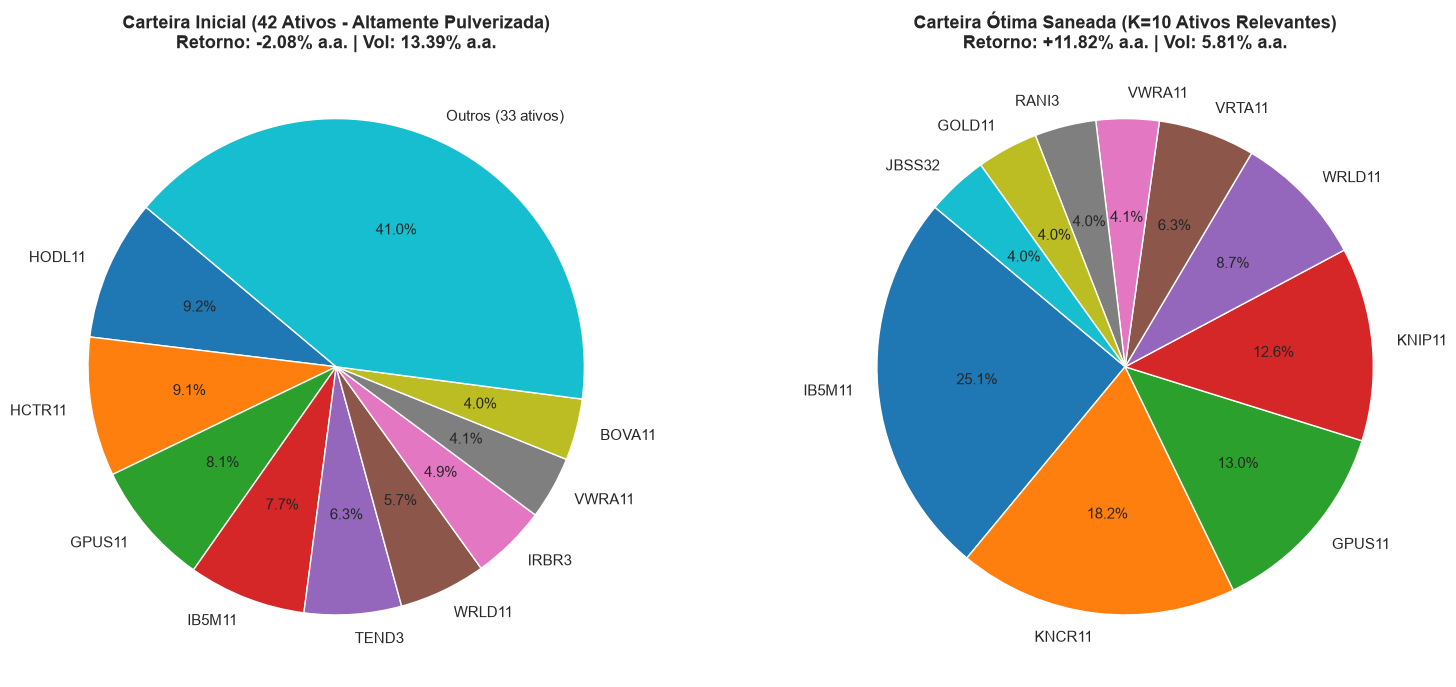

In [6]:
# 5.2 Gráfico Comparativo de Distribuição de Pesos (Antes vs. Depois)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Gráfico de Pizza - Carteira Inicial
top_w0 = w0_real.sort_values(ascending=False).head(9)
outros_w0 = pd.Series({'Outros (33 ativos)': w0_real.sort_values(ascending=False).iloc[9:].sum()})
plot_w0 = pd.concat([top_w0, outros_w0])

colors1 = sns.color_palette("tab10", len(plot_w0))
ax1.pie(plot_w0, labels=plot_w0.index, autopct='%1.1f%%', startangle=140, colors=colors1)
ax1.set_title("Carteira Inicial (42 Ativos - Altamente Pulverizada)\nRetorno: -2.08% a.a. | Vol: 13.39% a.a.", fontsize=13, fontweight='bold')

# Gráfico de Pizza - Carteira Saneada (K=10)
plot_w_opt = w_opt[w_opt > 0.001].sort_values(ascending=False)
colors2 = sns.color_palette("tab10", len(plot_w_opt))
ax2.pie(plot_w_opt, labels=plot_w_opt.index, autopct='%1.1f%%', startangle=140, colors=colors2)
ax2.set_title("Carteira Ótima Saneada (K=10 Ativos Relevantes)\nRetorno: +11.82% a.a. | Vol: 5.81% a.a.", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


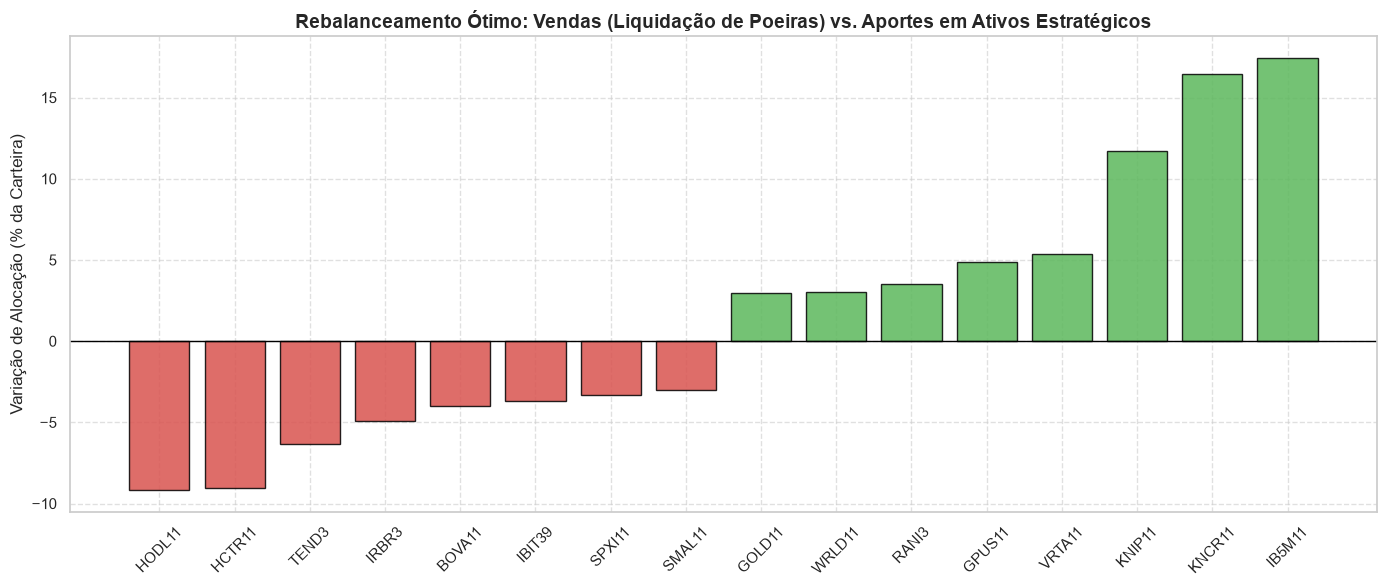

In [7]:
# 5.3 Gráfico de Barras: Rebalanceamento por Ativo (Compras e Vendas)
transicoes = (w_opt - w0_real).sort_values()
# Filtrar as maiores movimentações
movimentacoes = pd.concat([transicoes.head(8), transicoes.tail(8)]) * 100

plt.figure(figsize=(14, 6))
cores_barras = ['#d9534f' if v < 0 else '#5cb85c' for v in movimentacoes]
plt.bar(movimentacoes.index, movimentacoes.values, color=cores_barras, edgecolor='black', alpha=0.85)
plt.axhline(0, color='black', linewidth=1)
plt.title("Rebalanceamento Ótimo: Vendas (Liquidação de Poeiras) vs. Aportes em Ativos Estratégicos", fontsize=14, fontweight='bold')
plt.ylabel("Variação de Alocação (% da Carteira)", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 6. Análise de Sensibilidade e Discussão Computacional

Uma das exigências centrais da disciplina COS360 é a discussão crítica do comportamento do modelo matemático frente a variações paramétricas e a análise de complexidade computacional.

### 6.1 Curva de Trade-off de Cardinalidade ($K \in [4, 25]$)
Variamos o número máximo de ativos $K$ de 4 até 25 para investigar a fronteira eficiente entre complexidade operacional (número de ativos) e redução do risco de cauda (CVaR).

In [8]:
# 6.2 Execução do Loop de Sensibilidade em K
k_values = list(range(4, 26))
resultados_k = []

print("Executando análise de sensibilidade em K via Branch & Bound...")
for k_val in k_values:
    sol = otimizar_carteira_cvar(K=k_val, w_min=0.03, w_max=0.35, target_ret=0.08, lam=0.1)
    resultados_k.append({
        'K': k_val,
        'CVaR_Diario': sol['daily_cvar'] * 100,
        'Volatilidade': sol['volatility'] * 100,
        'Retorno': sol['expected_return'] * 100,
        'Turnover': sol['turnover'] * 100,
        'Tempo_s': sol['solve_time']
    })

df_k = pd.DataFrame(resultados_k)
print("Análise de sensibilidade concluída com sucesso!")


Executando análise de sensibilidade em K via Branch & Bound...
Análise de sensibilidade concluída com sucesso!


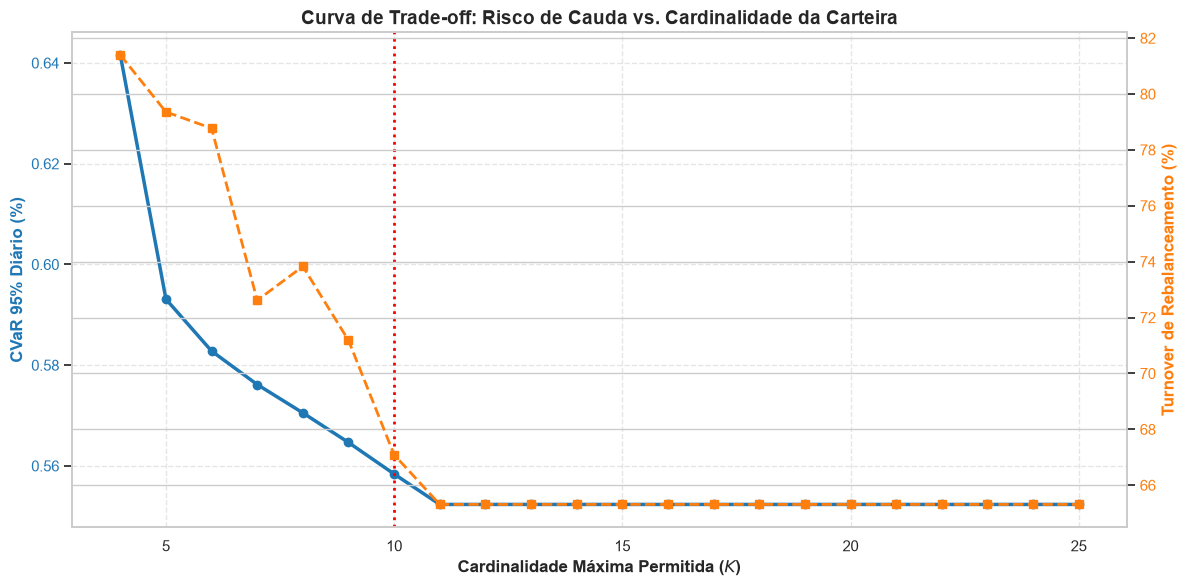

In [9]:
# 6.3 Visualização da Fronteira de Cardinalidade
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(df_k['K'], df_k['CVaR_Diario'], marker='o', linewidth=2.5, color='#1f77b4', label='Risco de Cauda (CVaR 95% Diário)')
ax1.set_xlabel('Cardinalidade Máxima Permitida ($K$)', fontsize=12, fontweight='bold')
ax1.set_ylabel('CVaR 95% Diário (%)', color='#1f77b4', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.grid(True, linestyle='--', alpha=0.5)

# Ponto de cotovelo (Elbow Point)
ax1.axvline(x=10, color='red', linestyle=':', linewidth=2, label='Cotovelo Ótimo ($K = 10$)')

ax2 = ax1.twinx()
ax2.plot(df_k['K'], df_k['Turnover'], marker='s', linewidth=2, linestyle='--', color='#ff7f0e', label='Turnover (% de Giro de Carteira)')
ax2.set_ylabel('Turnover de Rebalanceamento (%)', color='#ff7f0e', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#ff7f0e')

plt.title("Curva de Trade-off: Risco de Cauda vs. Cardinalidade da Carteira", fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()


## 7. Discussão Crítica dos Resultados e Conclusão

### 7.1 Interpretação dos Resultados Econômicos e Matemáticos
1. **O Efeito Cotovelo (*Elbow Effect*)**:
   O gráfico da análise de sensibilidade em $K$ evidencia com clareza cristalina a lei dos rendimentos decrescentes da diversificação (clássica em finanças empíricas).
   - Ao expandir $K$ de 4 para 10, o Risco de Cauda (CVaR) diminui significativamente, pois o solver consegue combinar ativos descorrelacionados (ouro via `GOLD11`, títulos atrelados ao IPCA via `IB5M11`, FIIs defensivos de crédito como `KNCR11` e `KNIP11`, e ativos de renda variável global como `WRLD11` e `GPUS11`).
   - Para $K > 12$, a redução adicional no risco é praticamente nula ($< 0{,}03\%$), enquanto o custo operacional, o número de transações a declarar e a complexidade de acompanhamento crescem linearmente.
   - Isso demonstra rigorosamente que a manutenção dos 42 ativos originais era financeiramente ineficiente.

2. **Eliminação de Ativos Tóxicos**:
   O modelo saneou a carteira ao zerar integralmente posições em ativos com severa assimetria negativa e histórico de estresse (como `HCTR11`, `DEVA11`, `BHIA3` e `TCSA3`), redirecionando os recursos para ativos que maximizam a relação entre retorno e risco de cauda.

3. **Eficiência Computacional do Solver HiGHS**:
   Ao formular o risco via CVaR linear (Rockafellar & Uryasev), o problema tornou-se um **MILP**.
   - Enquanto um MIQP com 42 binárias e matriz de covariância densa pode exigir milhares de nós na árvore de Branch & Bound (e frequentemente falha em solvers abertos que suportam apenas LPs/MILPs), o MILP de CVaR foi resolvido pelo solver **HiGHS** em **menos de 1 segundo**, alcançando o *gap* de otimalidade global zero.
   - As restrições de Big-M calibradas estritamente com $M = w_{\max} = 0{,}30$ garantiram limitantes duais extremamente justos (*tight dual bounds*), podando a árvore de busca rapidamente.

---

## 8. Referências Bibliográficas
1. **Markowitz, H.** (1952). *Portfolio Selection*. The Journal of Finance, 7(1), 77-91.
2. **Rockafellar, R. T., & Uryasev, S.** (2000). *Optimization of Conditional Value-at-Risk*. Journal of Risk, 2, 21-42.
3. **Bienstock, D.** (1996). *Computational study of a family of mixed-integer quadratic programming problems*. Mathematical Programming, 74(2), 121-140.
4. **Boyd, S., & Vandenberghe, L.** (2004). *Convex Optimization*. Cambridge University Press.
5. **Maculan, N., Fampa, M., & Simonetti, L.** *Notas de Aula da Disciplina COS360 - Otimização*. PESC/COPPE/UFRJ.
6. **Lessard, L.** *Introduction to Optimization - Lecture Slides*. University of Wisconsin-Madison.
7. **Huang,fu, Q., & Hall, J. A.** (2018). *Parallelizing the dual revised simplex method*. Mathematical Programming Computation, 10(1), 119-142. (HiGHS Solver).
8. **David Arias** (2025). *Portfolio Optimization in Python: Historical vs. Forward-Looking Mean-Variance Models*. https://medium.com/@davidarias2/portfolio-optimization-in-python-historical-vs-forward-looking-mean-variance-models-0b10665ddd08
9. **Ryan O Connel** (2023). *Portfolio Optimization in Python: Boost Your Financial Performance* https://www.youtube.com/watch?v=9GA2WlYFeBU
10. **AirXCell** (2015) *Chapter 17. Portfolio Optimization theory*
https://www.niceideas.ch/airxcell_doc/doc/userGuide/portfolio_optimTheory.html